In [1]:
# https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud?utm_source=chatgpt.com


#### imbalanced dataset:

`One class has much higher samples than another class`

| Class    | Count |
| -------- | ----- |
| No Fraud | 990   |
| Fraud    | 10    |

**Highly Imbalnced**

Suppose model predicts:

Always "No Fraud"

Accuracy becomes:

**1000/990=99%**
- But Model completely failed to detect fraud
- Accuracy becomes misleading in imbalanced datasets.

#### Real world examples
| Problem            | Minority Class |
| ------------------ | -------------- |
| Fraud Detection    | Fraud          |
| Cancer Detection   | Cancer         |
| Spam Detection     | Spam           |
| Disease Prediction | Disease        |
| Cyber Security     | Attack         |


In [5]:
#!pip install imbalanced-learn
!pip install --upgrade scikit-learn imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable

   ---------------------------------------- 0/2 [sklearn-compat]
   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbal

In [35]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

In [36]:
import sklearn
import imblearn
print(sklearn.__version__)
print(imblearn.__version__)

1.8.0
0.14.1


In [37]:
df = pd.read_csv(r"./archive/creditcard.csv")
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [38]:
df.shape

(284807, 31)

### Check Class Distribution

In [39]:
print(df['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [40]:
df['Class'].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

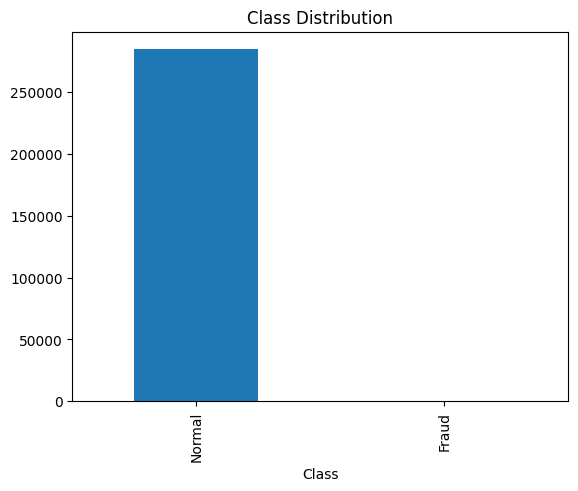

In [41]:
import matplotlib.pyplot as plt

df['Class'].value_counts().plot(kind='bar')

plt.title("Class Distribution")

plt.xticks([0,1], ['Normal','Fraud'])

plt.show()

### Features and target

In [42]:
X = df.drop('Class', axis=1)

y = df['Class']

### Train Test Split

In [48]:
X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [49]:
y_train.value_counts()

Class
0    227451
1       394
Name: count, dtype: int64

#### Why stratify=y?

Maintains same class ratio in train and test.

### Train Normal Model (Without Balancing)

In [50]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [52]:
y_pred_train = model.predict(X_train)
confusion_matrix(y_train, y_pred_train)

array([[227405,     46],
       [   136,    258]])

In [23]:
print("Accuracy:")

print(accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

Accuracy:
0.9991748885221726
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.79      0.71      0.75        98

    accuracy                           1.00     56962
   macro avg       0.89      0.86      0.87     56962
weighted avg       1.00      1.00      1.00     56962



**99% accuracy**

BUT:

Poor fraud recall

**Note : The model predicts majority class well but fails minority class.**

## Technique 1 — Random Undersampling

- Reduce majority class samples.
- | Before     | After     |
| ---------- | --------- |
| 990 Normal | 10 Normal |
| 10 Fraud   | 10 Fraud  |


In [24]:
undersampler = RandomUnderSampler(random_state=42)

X_under, y_under = undersampler.fit_resample(

    X_train,
    y_train
)

#### Checking New Distribution

In [25]:
print(pd.Series(y_under).value_counts())

Class
0    394
1    394
Name: count, dtype: int64


### Model Training

In [26]:
model_under = LogisticRegression(max_iter=1000)

model_under.fit(X_under, y_under)

pred_under = model_under.predict(X_test)

print(classification_report(y_test, pred_under))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98     56864
           1       0.04      0.92      0.07        98

    accuracy                           0.96     56962
   macro avg       0.52      0.94      0.52     56962
weighted avg       1.00      0.96      0.98     56962



C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Advantages

✅ Faster
✅ Balanced dataset

#### Disadvantages

❌ Loses information
❌ Removes useful majority samples

## Technique 2 — Random Oversampling
Duplicate minority samples.
| Before     | After      |
| ---------- | ---------- |
| 990 Normal | 990 Normal |
| 10 Fraud   | 990 Fraud  |


In [27]:
oversampler = RandomOverSampler(random_state=42)

X_over, y_over = oversampler.fit_resample(

    X_train,
    y_train
)

In [28]:
print(pd.Series(y_over).value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64


### Model Building

In [29]:
model_over = LogisticRegression(max_iter=1000)

model_over.fit(X_over, y_over)

pred_over = model_over.predict(X_test)

print(classification_report(y_test, pred_over))

              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.92      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962



C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Advantages

✅ No data loss

#### Disadvantages

❌ Overfitting possible
❌ Duplicate samples

## Technique 3 — SMOTE (Synthetic Minority Oversampling Technique)
Instead of copying minority samples:

Generate NEW synthetic minority samples

- Oversampling photocopies data.
- SMOTE creates new artificial students.

Suppose fraud points:

    - A ----- B

SMOTE creates new point:

    - between A and B

In [30]:
smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(

    X_train,
    y_train
)

#### Check Distribution

In [31]:
print(pd.Series(y_smote).value_counts())

Class
0    227451
1    227451
Name: count, dtype: int64


### Train Model

In [32]:
model_smote = LogisticRegression(max_iter=1000)

model_smote.fit(X_smote, y_smote)

pred_smote = model_smote.predict(X_test)

print(classification_report(y_test, pred_smote))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     56864
           1       0.13      0.90      0.22        98

    accuracy                           0.99     56962
   macro avg       0.56      0.94      0.61     56962
weighted avg       1.00      0.99      0.99     56962



C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Advantages

✅ Better generalization
✅ No exact duplicates
✅ Most popular technique

#### Disadvantages

❌ Slightly slower
❌ Synthetic data may introduce noise

## Technique 4 — Class Weights

Minority class mistakes are more costly

In [33]:
weighted_model = LogisticRegression(

    class_weight='balanced',

    max_iter=1000
)

weighted_model.fit(X_train, y_train)

pred_weighted = weighted_model.predict(X_test)

print(classification_report(y_test, pred_weighted))

# SVC = SVC(class_weight="balanced")

# DT = DecisionTreeClassifier(
#     class_weight="balanced"
# )

# RF = RandomForestClassifier(
#     class_weight="balanced"
# )

              precision    recall  f1-score   support

           0       1.00      0.97      0.98     56864
           1       0.05      0.91      0.09        98

    accuracy                           0.97     56962
   macro avg       0.52      0.94      0.54     56962
weighted avg       1.00      0.97      0.98     56962



C:\Users\DELL\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Advantages

✅ No resampling needed
✅ Very elegant solution

#### Disadvantages

❌ May not always improve performance

### How does class_weight="balanced" work?
It automatically calculates weights for each class based on the number of samples.

The formula is:
$$
\[
Weight = \frac{Total\ Samples}{Number\ of\ Classes \times Samples\ in\ Class}
\]
$$

For our example: 
950 - majority
50 - minority
$$
Normal class weight:
\[
\frac{1000}{2\times950}=0.526
\]$$
$$
Fraud class weight:
\[
\frac{1000}{2\times50}=10
\]
$$

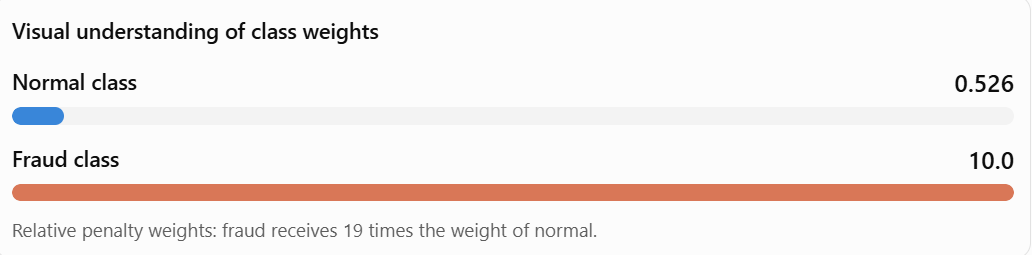
#### What does this mean?

If the model makes a mistake on a fraud transaction, that mistake receives a much higher penalty than a mistake on a normal transaction.

As a result, the model pays more attention to identifying the minority class.

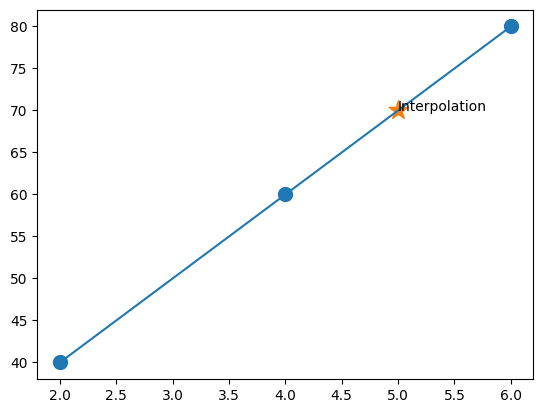

In [34]:
import matplotlib.pyplot as plt

x = [2,4,6]
y = [40,60,80]

plt.scatter(x,y,s=100)

plt.plot(x,y)

plt.scatter(5,70,s=200,marker='*')

plt.text(5,70,'Interpolation')

plt.show()